In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import (average_precision_score, precision_recall_curve,
                             precision_score, recall_score, f1_score, confusion_matrix)
OUT = Path("../reports/fraud"); FIG = OUT / "figures"
raw = pd.read_csv("../data/raw/paysim/PS_20174392719_1491204439457_log.csv")
df = raw[raw.type.isin(["TRANSFER", "CASH_OUT"])].copy()
df["hour"] = df.step % 24
df["is_transfer"] = (df.type == "TRANSFER").astype(int)
df["amt_to_oldbal"] = df.amount / (df.oldbalanceOrg + 1)
df["drains_account"] = (df.amount >= df.oldbalanceOrg).astype(int)
df["dest_empty"] = (df.oldbalanceDest == 0).astype(int)
df["errBalOrig"] = df.newbalanceOrig + df.amount - df.oldbalanceOrg
df["errBalDest"] = df.oldbalanceDest + df.amount - df.newbalanceDest
FEAT_A = ["is_transfer", "amount", "oldbalanceOrg", "oldbalanceDest", "hour",
          "amt_to_oldbal", "drains_account", "dest_empty"]
FEAT_B = FEAT_A + ["newbalanceOrig", "newbalanceDest", "errBalOrig", "errBalDest"]
train = df[df.step <= 450]; val = df[(df.step > 450) & (df.step <= 600)]; test = df[df.step > 600]
for n, d in [("train", train), ("val", val), ("test", test)]:
    print(n, len(d), int(d.isFraud.sum()), f"{d.isFraud.mean():.3%}")

train 2626155 5057 0.193%
val 100704 1556 1.545%
test 43550 1600 3.674%


In [2]:
COST_FN, COST_FP = 5, 1
def pick_threshold(y, s):
    cands = np.unique(np.quantile(s, np.linspace(0.90, 0.9999, 400)))
    return min(cands, key=lambda t: COST_FN*((s < t) & (y == 1)).sum() + COST_FP*((s >= t) & (y == 0)).sum())
def evaluate(name, y, s, thr):
    pred = (s >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    return dict(model=name, pr_auc=average_precision_score(y, s), precision=precision_score(y, pred, zero_division=0),
                recall=recall_score(y, pred), f1=f1_score(y, pred), TP=tp, FP=fp, FN=fn, TN=tn)
y_val, y_te = val.isFraud.values, test.isFraud.values
rows, scores = [], {}
rows.append(evaluate("Rule: isFlaggedFraud", y_te, test.isFlaggedFraud.values.astype(float), 0.5))
rows.append(evaluate("Rule: amount > 200,000", y_te, (test.amount.values > 200000).astype(float), 0.5))

In [3]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.linear_model import LogisticRegression
lr = make_pipeline(FunctionTransformer(np.log1p), StandardScaler(),
                   LogisticRegression(class_weight="balanced", max_iter=1000))
lr.fit(train[FEAT_A], train.isFraud)
s_val, s_te = lr.predict_proba(val[FEAT_A])[:, 1], lr.predict_proba(test[FEAT_A])[:, 1]
scores["Logistic Regression (A)"] = s_te
rows.append(evaluate("Logistic Regression (A)", y_te, s_te, pick_threshold(y_val, s_val)))

In [4]:
from sklearn.ensemble import IsolationForest
iso = IsolationForest(n_estimators=200, random_state=42, n_jobs=-1)
iso.fit(train[FEAT_A].sample(300_000, random_state=42))
s_val, s_te = -iso.score_samples(val[FEAT_A]), -iso.score_samples(test[FEAT_A])
scores["Isolation Forest (A)"] = s_te
rows.append(evaluate("Isolation Forest (A)", y_te, s_te, pick_threshold(y_val, s_val)))

In [5]:
pd.DataFrame(rows).round(4)

,model,pr_auc,precision,recall,f1,TP,FP,FN,TN
0,Rule: isFlaggedFraud,0.0416,1.0000,0.0050,0.0100,8,0,1592,41950
1,"Rule: amount > 200,000",0.0503,0.0570,0.6675,0.1051,1068,17661,532,24289
2,Logistic Regression (A),0.7110,0.6879,0.8019,0.7405,1283,582,317,41368
3,Isolation Forest (A),0.5019,0.6070,0.4362,0.5076,698,452,902,41498


In [6]:
import xgboost as xgb
spw = (train.isFraud == 0).sum() / (train.isFraud == 1).sum()
for tag, feats in [("A deployable", FEAT_A), ("B with post-transaction balances", FEAT_B)]:
    m = xgb.XGBClassifier(n_estimators=500, max_depth=6, learning_rate=0.1, subsample=0.8, colsample_bytree=0.8,
                          scale_pos_weight=spw, tree_method="hist", eval_metric="aucpr",
                          early_stopping_rounds=30, random_state=42, n_jobs=-1)
    m.fit(train[feats], train.isFraud, eval_set=[(val[feats], val.isFraud)], verbose=False)
    s_val, s_te = m.predict_proba(val[feats])[:, 1], m.predict_proba(test[feats])[:, 1]
    scores[f"XGBoost ({tag})"] = s_te
    rows.append(evaluate(f"XGBoost ({tag})", y_te, s_te, pick_threshold(y_val, s_val)))
    print(tag, "best iteration:", m.best_iteration)

A deployable best iteration: 183
B with post-transaction balances best iteration: 13


,model,pr_auc,precision,recall,f1,TP,FP,FN,TN,cost_5FN_1FP
0,Rule: isFlaggedFraud,NaN,1.0000,0.0050,0.0100,8,0,1592,41950,7960
1,"Rule: amount > 200,000",NaN,0.0570,0.6675,0.1051,1068,17661,532,24289,20321
2,Logistic Regression (A),0.7110,0.6879,0.8019,0.7405,1283,582,317,41368,2167
3,Isolation Forest (A),0.5019,0.6070,0.4362,0.5076,698,452,902,41498,4962
4,XGBoost (A deployable),0.9968,0.9638,0.9975,0.9803,1596,60,4,41890,80
5,XGBoost (B with post-transaction balances),1.0000,0.9932,1.0000,0.9966,1600,11,0,41939,11


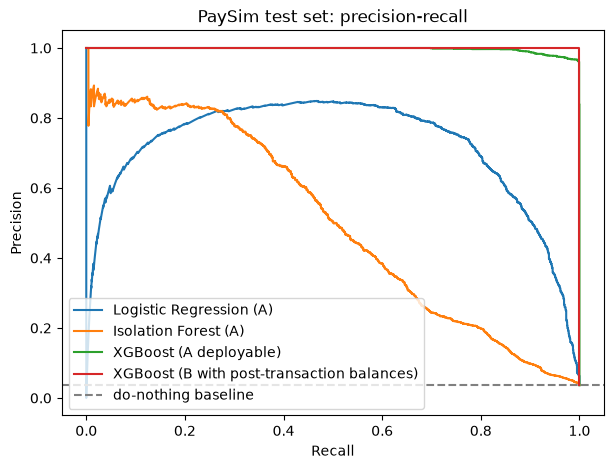

In [7]:
res = pd.DataFrame(rows)
res["cost_5FN_1FP"] = 5 * res.FN + res.FP
res.loc[res.model.str.startswith("Rule"), "pr_auc"] = np.nan
res = res.round(4)
res.to_csv(OUT / "paysim_benchmark.csv", index=False)
display(res)
plt.figure(figsize=(7, 5))
for name, s in scores.items():
    p, r, _ = precision_recall_curve(y_te, s); plt.plot(r, p, label=name)
plt.axhline(y_te.mean(), color="gray", linestyle="--", label="do-nothing baseline")
plt.xlabel("Recall"); plt.ylabel("Precision"); plt.legend(); plt.title("PaySim test set: precision-recall")
plt.savefig(FIG / "paysim_pr_curves.png", dpi=150, bbox_inches="tight"); plt.show()

In [8]:
def fit_eval(feats, tag):
    m = xgb.XGBClassifier(n_estimators=500, max_depth=6, learning_rate=0.1, subsample=0.8, colsample_bytree=0.8,
                          scale_pos_weight=spw, tree_method="hist", eval_metric="aucpr",
                          early_stopping_rounds=30, random_state=42, n_jobs=-1)
    m.fit(train[feats], train.isFraud, eval_set=[(val[feats], val.isFraud)], verbose=False)
    s_te = m.predict_proba(test[feats])[:, 1]
    print(f"{tag}: test PR-AUC = {average_precision_score(y_te, s_te):.4f}")
    return m
mA = fit_eval(FEAT_A, "A (all 8 features)")
print(pd.Series(mA.feature_importances_, index=FEAT_A).sort_values(ascending=False).round(3))
fit_eval([f for f in FEAT_A if f != "hour"], "A without hour")
fit_eval([f for f in FEAT_A if f not in ("hour", "amt_to_oldbal", "drains_account")], "A without hour and drain features")

A (all 8 features): test PR-AUC = 0.9968
drains_account    0.462
amt_to_oldbal     0.367
oldbalanceOrg     0.094
amount            0.027
is_transfer       0.022
dest_empty        0.017
hour              0.006
oldbalanceDest    0.005
dtype: float32
A without hour: test PR-AUC = 0.9956
A without hour and drain features: test PR-AUC = 0.9706


,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.8
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",30
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'aucpr'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None
